# 06 Bid vs Paid

**Question:** How much do we overbid, and how does win rate change with bid level?

Task 2, step 6: **the gap between bid price and paying price, win rate at each bid level, and the effect of floor prices.** This notebook feeds the **auction insights** tab.

**Auction basics (iPinYou, 2013):** these exchanges ran **second-price auctions**. The winner pays the *second-highest bid* (or the publisher's **floor price**, if that is higher), not its own bid. So:
* **bid − paid** is how much we *offered but didn't need to*. It is room for **bid shading**, and it would be real money if the exchanges moved to first-price auctions, as most did after 2017.
* **The paying price is the market price** of an impression we won: the highest competing bid, or the floor.
* **Win rate** = impressions won / bids. Bidding higher wins more auctions, but every extra win costs more.
* **Censoring:** we only see the paying price on auctions we *won*. On lost auctions the market price was above our bid, but we never see by how much. A "bid landscape" built from won impressions is therefore a **lower bound**.

**Method:** like Notebook 03, two small frequency tables are built in one pass per log (counts per campaign × exchange × bid × floor, plus the paying price for impressions). Everything below is computed exactly from them. The database is opened read-only. Prices are scaled per-1,000-impression values, so compare them with each other, not as money.

### Setup

In [1]:
# CELL 1: setup (read-only connection)
from pathlib import Path
import os, re, shutil, signal, time
import duckdb
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

KILL_STALE = False
MIN_BIDS = 1_000             # win rate shown for cells with at least this many bids
PROJECT_ROOT = Path.cwd().parent
# Where the data comes from (the views raw_* and typed_* are the same either way):
#   1. data/processed/ipinyou.duckdb, the database the loading notebook built, if it is still there
#   2. otherwise the pipeline's hourly Parquet files in data/interim, read in memory (pipeline_views.py)
DB_PATH = PROJECT_ROOT / "data" / "processed" / "ipinyou.duckdb"
BID_DIR = PROJECT_ROOT / "data" / "interim" / "bid_parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

if "con" in globals():
    try:
        con.close()
    except Exception:
        pass

def open_db(path, kill_stale=False, retries=5):
    for attempt in range(retries):
        try:
            return duckdb.connect(str(path), read_only=True)
        except duckdb.IOException as e:
            m = re.search(r"PID (\d+)", str(e))
            if "lock" not in str(e).lower() or m is None:
                raise
            print(f"The database is locked by another Python process (PID {m.group(1)}).")
            if not kill_stale:
                print("Shut down the other notebook (Jupyter > Running tab > Shut Down), "
                      "or set KILL_STALE = True and run this cell again.")
                raise
            os.kill(int(m.group(1)), signal.SIGTERM)
            time.sleep(2)
    raise RuntimeError("Could not get the database lock")

if DB_PATH.exists():
    con = open_db(DB_PATH, kill_stale=KILL_STALE)
    DATA_SOURCE = f"{DB_PATH.name} (the loading notebook's database)"
else:
    from pipeline_views import create_views
    con = duckdb.connect()   # in memory: reads the Parquet files, writes nothing to disk
    DATA_SOURCE = create_views(con, PROJECT_ROOT)
con.execute("SET preserve_insertion_order=false")
try:
    con.execute("SET enable_progress_bar=false")
except Exception:
    pass
q = lambda sql: con.execute(sql).df()

views = set(q("SELECT view_name FROM duckdb_views() WHERE NOT internal")["view_name"])
assert "typed_imp" in views, "Run the loading cells first"
if "typed_bid" not in views:
    files = [str(p) for p in sorted(BID_DIR.glob("bid_*.parquet"))]
    files += [str(p) for p in sorted(BID_DIR.glob("bid_*/part_*.parquet")) if not p.parent.name.endswith(".partial")]
    t = lambda c: f"TRY_CAST(nullif(nullif({c}, ''), 'null') AS BIGINT) AS {c}"
    con.execute("CREATE TEMP VIEW typed_bid AS SELECT " + ", ".join(t(c) for c in
                ["advertiser_id", "ad_exchange", "bidding_price", "ad_slot_floor_price"])
                + " FROM read_parquet([" + ", ".join(f"'{x}'" for x in files) + "])")
    print("typed_bid rebuilt in memory from", len(files), "Parquet files")

def wilson(k, n, z=1.959964):
    k, n = np.asarray(k, float), np.asarray(n, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        d = 1 + z**2 / n
        c = (p + z**2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return np.where(n > 0, c - h, np.nan), np.where(n > 0, c + h, np.nan)

def band(f):
    f = np.asarray(f)
    return np.select([f == 0, f <= 10, f <= 50, f <= 100, f <= 200],
                     ["a: 0", "b: 1-10", "c: 11-50", "d: 51-100", "e: 101-200"], "f: 200+")

try:
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mt
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.color": "#e6e5e0", "axes.titlesize": 10, "axes.titleweight": "bold",
                         "axes.titlelocation": "left", "font.size": 9})
except ImportError:
    plt = None
BLUE, ORANGE, GREY, INK2 = "#2a78d6", "#eb6834", "#8a8984", "#52514e"
CAMP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cf6", "#c2410c"]

def save(fig, name):
    try:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    except OSError:
        print(f"(no disk space: {name}.png not saved)")
print("Data:", DATA_SOURCE)

Data: ipinyou.duckdb (the loading notebook's database)


### 1. Frequency tables (one pass per log)

In [2]:
# CELL 2: counts per campaign x exchange x bid x floor (bids) and x paying price (impressions)
t0 = time.time()
B = q("""SELECT advertiser_id, ad_exchange, bidding_price AS bid, ad_slot_floor_price AS floor, count(*) AS bids
         FROM typed_bid GROUP BY ALL""")
print(f"bids: {B.bids.sum():,} -> {len(B):,} rows ({time.time() - t0:.0f}s)")
t0 = time.time()
I = q("""SELECT advertiser_id, ad_exchange, bidding_price AS bid, ad_slot_floor_price AS floor,
                paying_price AS paid, count(*) AS imps
         FROM typed_imp GROUP BY ALL""")
print(f"impressions: {I.imps.sum():,} -> {len(I):,} rows ({time.time() - t0:.0f}s)")
I["gap"] = I.bid - I.paid
I["floor_band"], B["floor_band"] = band(I.floor), band(B.floor)
I["floor_set_price"] = (I.paid == I.floor) & (I.floor > 0)
I["paid_above_bid"] = I.paid > I.bid
I["paid_below_floor"] = I.paid < I.floor

bids: 53,289,330 -> 979 rows (0s)
impressions: 12,237,087 -> 28,339 rows (0s)


### 2. The gap: what we bid vs what we paid

Per campaign:
* **average bid** vs **average paid** on won impressions, and the **median gap**
* **paid / bid**: the share of our bid we actually paid. **1 − paid/bid** is the *second-price saving*: what we would have paid extra in a first-price auction with the same bids.
* **rule-breaking rows**: a paying price *above* the bid shouldn't happen in a second-price auction. Notebook 01 flagged these, and here we see how much they weigh. They stay in the cost totals, because cost must match the dataset paper.

In [3]:
# CELL 3: gap summary per campaign and in total
def wq(values, weights, p):
    o = np.argsort(values)
    v, w = np.asarray(values)[o], np.asarray(weights, float)[o]
    return v[np.searchsorted(np.cumsum(w) / w.sum(), p - 1e-12)]

def gap_summary(d):
    n = d.imps.sum()
    return pd.Series({
        "impressions": n,
        "avg_bid": (d.bid * d.imps).sum() / n,
        "avg_paid": (d.paid * d.imps).sum() / n,
        "median_paid": wq(d.paid, d.imps, 0.5),
        "median_gap": wq(d.gap, d.imps, 0.5),
        "p10_gap": wq(d.gap, d.imps, 0.1),
        "p90_gap": wq(d.gap, d.imps, 0.9),
        "paid/bid": (d.paid * d.imps).sum() / (d.bid * d.imps).sum(),
        "second_price_saving": 1 - (d.paid * d.imps).sum() / (d.bid * d.imps).sum(),
        "share_paid_above_bid": d.loc[d.paid_above_bid, "imps"].sum() / n,
        "share_paid_below_floor": d.loc[d.paid_below_floor, "imps"].sum() / n,
        "share_floor_set_price": d.loc[d.floor_set_price, "imps"].sum() / n,
    })

gap = I.groupby("advertiser_id").apply(gap_summary, include_groups=False)
gap.loc["ALL"] = gap_summary(I)
display(gap.style.format({"impressions": "{:,.0f}", "avg_bid": "{:.1f}", "avg_paid": "{:.1f}", "median_paid": "{:.0f}",
                          "median_gap": "{:.0f}", "p10_gap": "{:.0f}", "p90_gap": "{:.0f}", "paid/bid": "{:.1%}",
                          "second_price_saving": "{:.1%}", "share_paid_above_bid": "{:.2%}",
                          "share_paid_below_floor": "{:.2%}", "share_floor_set_price": "{:.1%}"}))

print("Rule-breaking rows: paid above bid, by campaign and exchange (where do they come from?)")
pab = I[I.paid_above_bid].groupby(["advertiser_id", "ad_exchange"]).agg(
    impressions=("imps", "sum"), median_excess=("gap", lambda g: -np.median(g)))
pab["share_of_campaign_exchange"] = pab.impressions / I.groupby(["advertiser_id", "ad_exchange"]).imps.sum().reindex(pab.index)
display(pab.style.format({"impressions": "{:,.0f}", "median_excess": "{:.0f}", "share_of_campaign_exchange": "{:.2%}"}))

print("Gap by ad exchange (all campaigns):")
gx = I.groupby("ad_exchange").apply(gap_summary, include_groups=False)
display(gx[["impressions", "avg_bid", "avg_paid", "median_gap", "paid/bid", "share_floor_set_price", "share_paid_above_bid"]]
        .style.format({"impressions": "{:,.0f}", "avg_bid": "{:.1f}", "avg_paid": "{:.1f}", "median_gap": "{:.0f}",
                       "paid/bid": "{:.1%}", "share_floor_set_price": "{:.1%}", "share_paid_above_bid": "{:.2%}"}))

,impressions,avg_bid,avg_paid,median_paid,median_gap,p10_gap,p90_gap,paid/bid,second_price_saving,share_paid_above_bid,share_paid_below_floor,share_floor_set_price
advertiser_id,,,,,,,,,,,,
1458,"3,083,056",300.0,68.9,60,240,153,283,23.0%,77.0%,0.00%,0.91%,38.5%
3358,"1,742,104",232.7,92.4,77,160,31,213,39.7%,60.3%,4.85%,0.00%,1.6%
3386,"2,847,802",300.0,76.9,67,233,131,280,25.6%,74.4%,0.00%,1.27%,44.3%
3427,"2,593,765",236.2,81.1,76,164,66,219,34.3%,65.7%,3.14%,0.00%,2.0%
3476,"1,970,360",247.8,79.2,73,181,76,233,32.0%,68.0%,1.29%,0.01%,3.4%
ALL,"12,237,087",268.5,78.3,70,202,90,275,29.2%,70.8%,1.56%,0.52%,21.2%


Rule-breaking rows: paid above bid, by campaign and exchange (where do they come from?)


Gap by ad exchange (all campaigns):


,impressions,avg_bid,avg_paid,median_gap,paid/bid,share_floor_set_price,share_paid_above_bid
ad_exchange,,,,,,,
1,"3,878,242",260.7,95.7,173,36.7%,0.0%,3.89%
2,"3,962,486",268.9,77.0,205,28.6%,13.1%,0.81%
3,"4,396,359",274.9,64.3,220,23.4%,47.2%,0.19%


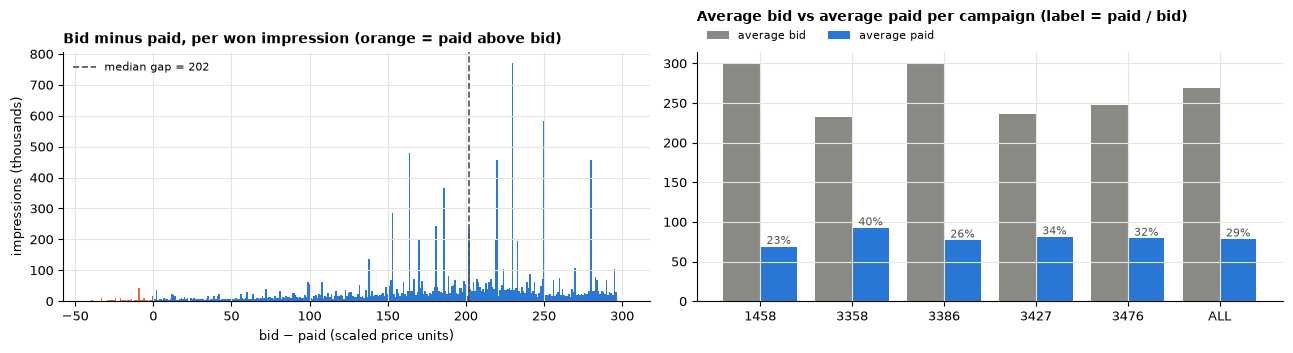

In [4]:
# CELL 4: chart - distribution of the gap, and paid vs bid
if plt:
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    g = I.groupby("gap").imps.sum()
    axes[0].bar(g.index, g.values / 1e3, width=1.0, color=np.where(g.index < 0, ORANGE, BLUE))
    axes[0].axvline(gap.loc["ALL", "median_gap"], color=INK2, ls="--", lw=1.2,
                    label=f"median gap = {gap.loc['ALL', 'median_gap']:.0f}")
    axes[0].set_title("Bid minus paid, per won impression (orange = paid above bid)")
    axes[0].set_xlabel("bid − paid (scaled price units)")
    axes[0].set_ylabel("impressions (thousands)")
    axes[0].legend(frameon=False, fontsize=8)
    ax = axes[1]
    x = np.arange(len(gap))
    ax.bar(x - 0.2, gap.avg_bid, width=0.4, color=GREY, label="average bid")
    ax.bar(x + 0.2, gap.avg_paid, width=0.4, color=BLUE, label="average paid")
    for xi, (b, p) in zip(x, zip(gap.avg_bid, gap.avg_paid)):
        ax.text(xi + 0.2, p, f"{p / b:.0%}", ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_xticks(x, gap.index.astype(str))
    ax.set_title("Average bid vs average paid per campaign (label = paid / bid)", pad=22)
    ax.legend(frameon=False, fontsize=8, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
    fig.tight_layout()
    save(fig, "06_gap")
    plt.show()

### 3. Win rate at each bid level

iPinYou campaigns bid a **handful of fixed prices**: 6 levels in Season 2 (Notebook 03). Win rate per level is therefore a small table, not a curve. Read it **per campaign**: each campaign uses its own levels and buys different inventory, so pooling levels across campaigns would mix the bid effect with the campaign effect.

The second view uses the **paying prices of won auctions** to sketch the bid landscape. For any bid *b*, it shows the share of today's wins that would have been won at *b* (those whose paying price is below *b*), and the spend that would have come with them. Lost auctions are invisible, so treat these curves as a **lower bound** for bids above the current levels.

In [5]:
# CELL 5: win rate per campaign x bid level (with 95% CI)
FEW_LEVELS = B.bid.nunique() <= 20          # Season 2: 6 levels. Many levels -> 20-unit bins instead
lvl_of = (lambda s: s) if FEW_LEVELS else (lambda s: (s // 20) * 20)
if not FEW_LEVELS:
    print(f"{B.bid.nunique()} distinct bids: grouped into bins of 20 (bid column = bin start)")
wins = I.assign(bid=lvl_of(I.bid)).groupby(["advertiser_id", "bid"]).imps.sum()
bids_ = B.assign(bid=lvl_of(B.bid)).groupby(["advertiser_id", "bid"]).bids.sum()
WL = pd.concat([bids_, wins], axis=1).fillna(0).astype("int64").reset_index()
WL["share_of_campaign_bids"] = WL.bids / WL.groupby("advertiser_id").bids.transform("sum")
WL["win_rate"] = WL.imps / WL.bids.where(WL.bids > 0)
WL["win_lo"], WL["win_hi"] = wilson(WL.imps, WL.bids)
WL["avg_paid"] = I.assign(bid=lvl_of(I.bid)).groupby(["advertiser_id", "bid"]).apply(
    lambda d: (d.paid * d.imps).sum() / d.imps.sum(), include_groups=False).reindex(
    pd.MultiIndex.from_frame(WL[["advertiser_id", "bid"]])).values
WL["shown"] = WL.bids >= MIN_BIDS
display(WL[WL.shown].style.format({"bids": "{:,.0f}", "imps": "{:,.0f}", "share_of_campaign_bids": "{:.1%}",
                                   "win_rate": "{:.2%}", "win_lo": "{:.2%}", "win_hi": "{:.2%}", "avg_paid": "{:.1f}"})
        .hide(axis="index"))
lv = WL[WL.shown].groupby("advertiser_id").bid.nunique()
print("Bid levels used per campaign (with >= %s bids):" % f"{MIN_BIDS:,}", lv.to_dict())

print("Pooled over campaigns (mixes the bid effect with the campaign effect; for reference only):")
pooled = WL.groupby("bid")[["bids", "imps"]].sum()
pooled["win_rate"] = pooled.imps / pooled.bids
display(pooled.style.format({"bids": "{:,.0f}", "imps": "{:,.0f}", "win_rate": "{:.2%}"}))

advertiser_id,bid,bids,imps,share_of_campaign_bids,win_rate,win_lo,win_hi,avg_paid,shown
1458,300,"14,701,496","3,083,056",100.0%,20.97%,20.95%,20.99%,68.9,True
3358,227,"1,718,067","912,962",45.8%,53.14%,53.06%,53.21%,108.0,True
3358,238,"1,033,827","533,185",27.6%,51.57%,51.48%,51.67%,78.0,True
3358,241,"999,122","295,957",26.6%,29.62%,29.53%,29.71%,70.1,True
3386,300,"14,091,931","2,847,802",100.0%,20.21%,20.19%,20.23%,76.9,True
3427,227,"1,133,686","697,304",8.1%,61.51%,61.42%,61.60%,103.9,True
3427,238,"7,133,508","905,346",50.8%,12.69%,12.67%,12.72%,77.4,True
3427,241,"5,765,425","991,115",41.1%,17.19%,17.16%,17.22%,68.3,True
3476,238,"956,095","559,295",14.2%,58.50%,58.40%,58.60%,96.9,True
3476,249,"1,089,855","667,059",16.2%,61.21%,61.11%,61.30%,72.2,True


Bid levels used per campaign (with >= 1,000 bids): {1458: 1, 3358: 3, 3386: 1, 3427: 3, 3476: 3}
Pooled over campaigns (mixes the bid effect with the campaign effect; for reference only):


,bids,imps,win_rate
bid,,,
227,"2,851,753","1,610,266",56.47%
238,"9,123,430","1,997,826",21.90%
241,"6,764,547","1,287,072",19.03%
249,"1,089,855","667,059",61.21%
254,"4,666,318","744,006",15.94%
300,"28,793,427","5,930,858",20.60%


If each campaign capped its bid (second-price, same competition): how many wins and how much spend remain


advertiser_id,bid capped at paid-price percentile,cap,wins kept,spend kept,avg paid on kept wins
1458,p50,60,50%,24%,32.7
1458,p75,80,72%,46%,44.0
1458,p90,147,90%,71%,54.6
1458,p95,192,95%,83%,60.2
3358,p50,77,46%,21%,41.4
3358,p75,124,75%,49%,60.9
3358,p90,199,90%,74%,76.6
3358,p95,231,95%,87%,84.3
3386,p50,67,50%,22%,34.1
3386,p75,90,75%,46%,47.8


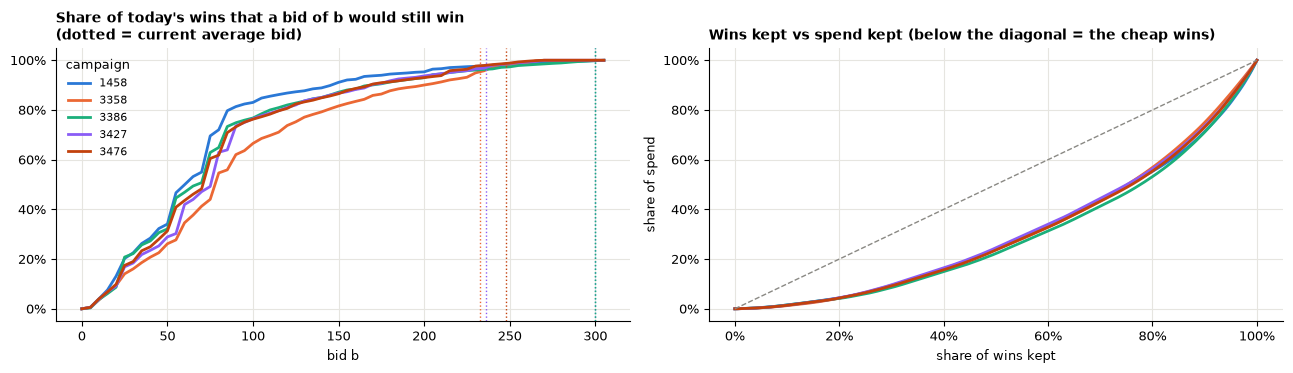

In [6]:
# CELL 6: bid landscape from won auctions - what if we had bid b?
grid = np.arange(0, int(I.paid.max()) + 10, 5)
rows = []
for adv in sorted(I.advertiser_id.unique()):
    d = I[I.advertiser_id == adv]
    pc = d.groupby("paid").imps.sum().sort_index()
    cum_imps = pc.cumsum()
    cum_spend = (pc * pc.index).cumsum()
    n, spend = pc.sum(), (pc * pc.index).sum()
    cur_bid = (d.bid * d.imps).sum() / n
    cur_wr = d.imps.sum() / B[B.advertiser_id == adv].bids.sum()
    for b in grid:
        k = pc.index.searchsorted(b, side="left") - 1            # paid < b
        kept = cum_imps.iloc[k] if k >= 0 else 0
        kept_spend = cum_spend.iloc[k] if k >= 0 else 0
        rows.append({"advertiser_id": adv, "bid_b": b, "share_of_wins_kept": kept / n,
                     "est_win_rate": cur_wr * kept / n, "share_of_spend": kept_spend / spend,
                     "current_avg_bid": cur_bid, "current_win_rate": cur_wr})
LAND = pd.DataFrame(rows)

# what-if table: lowering every bid to a cap
caps = []
for adv, d in I.groupby("advertiser_id"):
    for p in (0.5, 0.75, 0.9, 0.95):
        cap = wq(d.paid, d.imps, p)
        keep = d[d.paid < cap]
        caps.append({"advertiser_id": adv, "bid capped at paid-price percentile": f"p{int(p * 100)}", "cap": cap,
                     "wins kept": keep.imps.sum() / d.imps.sum(),
                     "spend kept": (keep.paid * keep.imps).sum() / (d.paid * d.imps).sum(),
                     "avg paid on kept wins": (keep.paid * keep.imps).sum() / keep.imps.sum()})
CAPS = pd.DataFrame(caps)
print("If each campaign capped its bid (second-price, same competition): how many wins and how much spend remain")
display(CAPS.style.format({"cap": "{:.0f}", "wins kept": "{:.0%}", "spend kept": "{:.0%}",
                           "avg paid on kept wins": "{:.1f}"}).hide(axis="index"))

if plt:
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    for (adv, d), c in zip(LAND.groupby("advertiser_id"), CAMP_COLORS):
        axes[0].plot(d.bid_b, d.share_of_wins_kept, color=c, lw=2, label=str(adv))
        axes[0].axvline(d.current_avg_bid.iloc[0], color=c, ls=":", lw=1)
        axes[1].plot(d.share_of_wins_kept, d.share_of_spend, color=c, lw=2, label=str(adv))
    axes[0].set_title("Share of today's wins that a bid of b would still win\n(dotted = current average bid)")
    axes[0].set_xlabel("bid b")
    axes[0].yaxis.set_major_formatter(mt.PercentFormatter(1.0))
    axes[0].legend(frameon=False, fontsize=8, title="campaign")
    axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
    axes[1].set_title("Wins kept vs spend kept (below the diagonal = the cheap wins)")
    axes[1].set_xlabel("share of wins kept")
    axes[1].set_ylabel("share of spend")
    for a in (axes[1].xaxis, axes[1].yaxis):
        a.set_major_formatter(mt.PercentFormatter(1.0))
    fig.tight_layout()
    save(fig, "06_bid_landscape")
    plt.show()

### 4. The effect of floor prices

The **floor price** (reserve price) is the minimum the publisher accepts. A high floor can:
* **lower the win rate**: fewer of our bids clear it
* **raise the paid price**: when the competition is thin, we pay the floor itself (*the floor set the price*)

Both are measured per floor band, and per campaign for win rate.

In [7]:
# CELL 7: floor bands - win rate, paid price, how often the floor set the price
fb_b = B.groupby("floor_band").bids.sum()
fb_i = I.groupby("floor_band").apply(lambda d: pd.Series({
    "imps": d.imps.sum(), "avg_paid": (d.paid * d.imps).sum() / d.imps.sum(),
    "median_paid": wq(d.paid, d.imps, 0.5), "avg_floor": (d.floor * d.imps).sum() / d.imps.sum(),
    "avg_paid_above_floor": ((d.paid - d.floor) * d.imps).sum() / d.imps.sum(),
    "share_floor_set_price": d.loc[d.floor_set_price, "imps"].sum() / d.imps.sum(),
    "paid/bid": (d.paid * d.imps).sum() / (d.bid * d.imps).sum()}), include_groups=False)
FL = pd.concat([fb_b, fb_i], axis=1)
FL["share_of_bids"] = FL.bids / FL.bids.sum()
FL["win_rate"] = FL.imps / FL.bids
FL["win_lo"], FL["win_hi"] = wilson(FL.imps, FL.bids)
display(FL[["bids", "share_of_bids", "imps", "win_rate", "win_lo", "win_hi", "avg_floor", "avg_paid", "median_paid",
            "avg_paid_above_floor", "share_floor_set_price", "paid/bid"]]
        .style.format({"bids": "{:,.0f}", "share_of_bids": "{:.1%}", "imps": "{:,.0f}", "win_rate": "{:.1%}",
                       "win_lo": "{:.1%}", "win_hi": "{:.1%}", "avg_floor": "{:.1f}", "avg_paid": "{:.1f}",
                       "median_paid": "{:.0f}", "avg_paid_above_floor": "{:.1f}", "share_floor_set_price": "{:.1%}",
                       "paid/bid": "{:.1%}"}))

print("Win rate by floor band, per campaign (cells with < %s bids hidden):" % f"{MIN_BIDS:,}")
cb = B.groupby(["advertiser_id", "floor_band"]).bids.sum()
ci = I.groupby(["advertiser_id", "floor_band"]).imps.sum()
CF = pd.concat([cb, ci], axis=1).fillna(0)
CF["win_rate"] = (CF.imps / CF.bids).where(CF.bids >= MIN_BIDS)
display(CF.win_rate.unstack("floor_band").style.format("{:.1%}", na_rep="–"))

# does a higher floor relative to our bid lower the win rate? (floor as a share of our bid)
B["floor_to_bid"] = pd.cut(B.floor / B.bid, [-0.01, 0, 0.1, 0.25, 0.5, 0.75, 1.0, 10],
                           labels=["0", "0-10%", "10-25%", "25-50%", "50-75%", "75-100%", ">100%"])
I["floor_to_bid"] = pd.cut(I.floor / I.bid, [-0.01, 0, 0.1, 0.25, 0.5, 0.75, 1.0, 10],
                           labels=["0", "0-10%", "10-25%", "25-50%", "50-75%", "75-100%", ">100%"])
FB = pd.concat([B.groupby("floor_to_bid", observed=False).bids.sum(),
                I.groupby("floor_to_bid", observed=False).imps.sum()], axis=1)
FB["win_rate"] = FB.imps / FB.bids.where(FB.bids > 0)
print("Win rate by floor as a share of our bid (all campaigns):")
display(FB.style.format({"bids": "{:,.0f}", "imps": "{:,.0f}", "win_rate": "{:.1%}"}, na_rep="–"))

,bids,share_of_bids,imps,win_rate,win_lo,win_hi,avg_floor,avg_paid,median_paid,avg_paid_above_floor,share_floor_set_price,paid/bid
floor_band,,,,,,,,,,,,
a: 0,"6,119,245",11.5%,"3,878,245",63.4%,63.3%,63.4%,0.0,95.7,79,95.7,0.0%,36.7%
b: 1-10,"11,806,896",22.2%,"3,227,873",27.3%,27.3%,27.4%,5.1,68.4,46,63.4,8.3%,25.4%
c: 11-50,"13,726,671",25.8%,"2,390,556",17.4%,17.4%,17.4%,35.9,51.6,50,15.6,41.7%,18.8%
d: 51-100,"20,752,384",38.9%,"2,412,369",11.6%,11.6%,11.6%,72.2,78.8,77,6.6,47.9%,28.8%
e: 101-200,"839,447",1.6%,"307,423",36.6%,36.5%,36.7%,146.7,156.2,153,9.5,51.2%,57.3%
f: 200+,"44,687",0.1%,"20,621",46.1%,45.7%,46.6%,253.8,257.8,250,4.0,79.5%,88.6%


Win rate by floor band, per campaign (cells with < 1,000 bids hidden):


floor_band,a: 0,b: 1-10,c: 11-50,d: 51-100,e: 101-200,f: 200+
advertiser_id,,,,,,
1458,82.3%,33.6%,14.7%,9.0%,52.2%,46.3%
3358,53.1%,49.0%,32.4%,33.8%,58.6%,55.5%
3386,63.9%,50.2%,19.3%,7.7%,71.0%,67.1%
3427,61.5%,11.9%,15.7%,19.4%,16.0%,13.6%
3476,58.5%,54.1%,17.7%,17.7%,67.6%,–


Win rate by floor as a share of our bid (all campaigns):


,bids,imps,win_rate
floor_to_bid,,,
0,"6,119,245","3,878,245",63.4%
0-10%,"17,905,300","4,153,713",23.2%
10-25%,"10,997,888","2,427,529",22.1%
25-50%,"17,650,133","1,584,519",9.0%
50-75%,"533,759","166,774",31.2%
75-100%,"83,005","26,307",31.7%
>100%,0,0,–


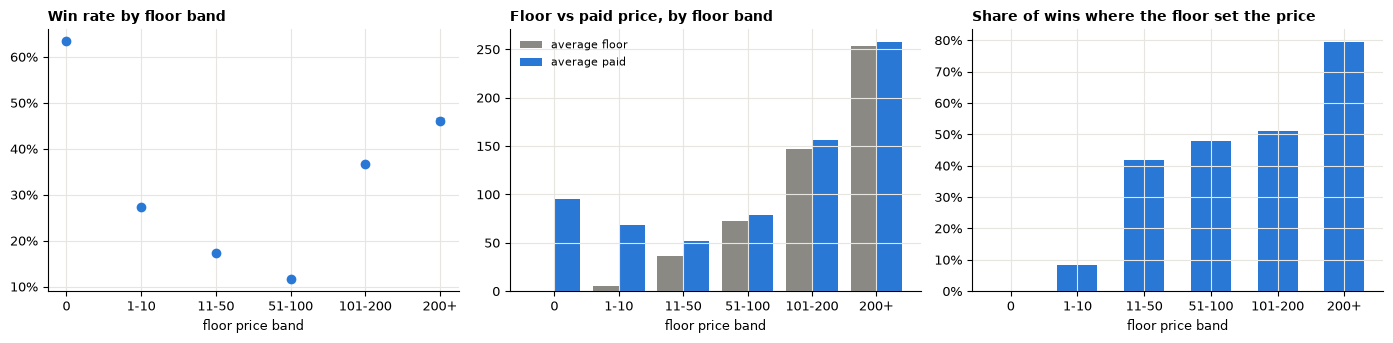

In [8]:
# CELL 8: floor charts
if plt:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
    x = np.arange(len(FL))
    axes[0].errorbar(x, FL.win_rate, yerr=[FL.win_rate - FL.win_lo, FL.win_hi - FL.win_rate], fmt="o", color=BLUE, capsize=3)
    axes[0].set_title("Win rate by floor band")
    axes[0].yaxis.set_major_formatter(mt.PercentFormatter(1.0))
    axes[1].bar(x - 0.2, FL.avg_floor, width=0.4, color=GREY, label="average floor")
    axes[1].bar(x + 0.2, FL.avg_paid, width=0.4, color=BLUE, label="average paid")
    axes[1].set_title("Floor vs paid price, by floor band")
    axes[1].legend(frameon=False, fontsize=8)
    axes[2].bar(x, FL.share_floor_set_price, color=BLUE, width=0.6)
    axes[2].set_title("Share of wins where the floor set the price")
    axes[2].yaxis.set_major_formatter(mt.PercentFormatter(1.0))
    for a in axes:
        a.set_xticks(x, [s.split(": ")[1] for s in FL.index])
        a.set_xlabel("floor price band")
    fig.tight_layout()
    save(fig, "06_floor")
    plt.show()

In [9]:
# Story candidates for Notebook 10 (the data story): a few structured findings, saved as a small JSON file
import json
def save_story(notebook, candidates):
    """candidates: list of dicts with title, number, chart (PNG name in reports/figures), confidence, meaning."""
    out = PROJECT_ROOT / "reports" / "findings"
    try:
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{notebook}.json").write_text(json.dumps(
            [{**c, "notebook": notebook} for c in candidates], indent=2, default=str), encoding="utf-8")
        print(f"Saved {len(candidates)} story candidate(s) to reports/findings/{notebook}.json")
    except OSError:
        print("(no disk space: story candidates not saved)")

def conf_from_p(p):
    if p != p:
        return "Low (not tested)"
    return "High (p < 0.001)" if p < 0.001 else ("Medium (p = %.3f)" % p if p < 0.05 else "Low (p = %.2f, not significant)" % p)

## Findings

Generated from the numbers above.

In [10]:
# CELL 9: findings
a = gap.loc["ALL"]
per = gap.drop(index="ALL")
lvl = WL[WL.shown]
multi = lvl.groupby("advertiser_id").filter(lambda d: len(d) >= 2)
cap90 = CAPS[CAPS["bid capped at paid-price percentile"] == "p90"]
fz, fh = FL.loc[FL.index.str.startswith("a")], FL.loc[FL.index.str.startswith(("e", "f"))]
F = [
    f"**We pay {a['paid/bid']:.0%} of what we bid.** Average bid {a.avg_bid:.0f} vs average paid {a.avg_paid:.0f} "
    f"(median gap {a.median_gap:.0f}). Under first-price auctions, the same bids would cost "
    f"{a.avg_bid / a.avg_paid:.1f}× as much, so bid shading toward the market price is the main lever. Confidence: high "
    f"(exact over {a.impressions:,.0f} impressions).",
    "**By campaign:** " + "; ".join(f"{i} pays {r['paid/bid']:.0%} of its bid (median paid {r.median_paid:.0f})"
                                   for i, r in per.iterrows()) + ".",
    (("**Win rate by bid level** (within campaign): " + "; ".join(
        f"{adv}: {int(d.bid.min())} → {d.sort_values('bid').win_rate.iloc[0]:.1%}, "
        f"{int(d.bid.max())} → {d.sort_values('bid').win_rate.iloc[-1]:.1%}"
        for adv, d in multi.groupby("advertiser_id")) + " (lowest and highest level). Higher levels win more, but the levels are confounded "
        "with time and inventory, so this is not a controlled test.") if len(multi) else
     "**Win rate by bid level:** each campaign uses essentially one bid level, so win rate vs bid can't be read "
     "within a campaign. The bid landscape from won prices is the substitute."),
    "**The most expensive wins:** capping each campaign's bid at its p90 paid price gives up the priciest 10% "
    "of today's wins and cuts spend to " + "; ".join(
        f"{int(r['advertiser_id'])}: {r['spend kept']:.0%}" for _, r in cap90.iterrows())
    + " of today's level. That is the trade-off for the bidding strategy: those wins cost "
    "more than average, and are worth it only if they convert better. (Based on won auctions only.)",
    f"**Floors:** {fz.share_of_bids.iloc[0]:.0%} of bids face no floor (win rate {fz.win_rate.iloc[0]:.1%}); "
    + (f"with floors above 100, win rate is {(fh.imps.sum() / fh.bids.sum()):.1%} and the floor set the price on "
       f"{(fh.share_floor_set_price * fh.imps).sum() / fh.imps.sum():.0%} of wins. " if fh.bids.sum() else "")
    + f"Overall, the floor set the price on {a.share_floor_set_price:.1%} of impressions.",
    f"**Data issue:** {a.share_paid_above_bid:.2%} of impressions paid more than the bid and "
    f"{a.share_paid_below_floor:.2%} paid less than the floor. Neither is possible in a clean second-price auction. "
    "They are kept in cost totals (to match the paper) but excluded from any bidding conclusion.",
]
if a.share_paid_above_bid == 0 and a.share_paid_below_floor == 0:
    F = F[:-1]
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(F, 1))))
save_story("06_bid_vs_paid", [
    {"title": f"We pay {a['paid/bid']:.0%} of what we bid",
     "number": f"average bid {a.avg_bid:.0f} vs average paid {a.avg_paid:.0f} (median gap {a.median_gap:.0f}); "
               + "; ".join(f"{i}: {r['paid/bid']:.0%}" for i, r in per.iterrows()),
     "chart": "06_gap.png", "confidence": f"High (exact over {a.impressions:,.0f} impressions)",
     "meaning": f"Second-price auctions hide a large overbid. Under first-price auctions the same bids would cost "
                f"{a.avg_bid / a.avg_paid:.1f}× as much, so bid shading toward the market price is the main saving."},
    {"title": "Floor prices set the price on high-floor inventory",
     "number": f"floor set the price on {a.share_floor_set_price:.1%} of all wins"
               + (f", and {(fh.share_floor_set_price * fh.imps).sum() / fh.imps.sum():.0%} of wins with floors above 100; "
                  f"win rate {(fh.imps.sum() / fh.bids.sum()):.1%} there vs {fz.win_rate.iloc[0]:.1%} with no floor"
                  if fh.bids.sum() else ""),
     "chart": "06_floor.png", "confidence": "High (exact counts)",
     "meaning": "High-floor inventory is priced by the publisher, not by competition. Check that its CTR justifies "
                "the price (Notebook 05, floor band) before bidding into it."},
])

1. **We pay 29% of what we bid.** Average bid 268 vs average paid 78 (median gap 202). Under first-price auctions, the same bids would cost 3.4× as much, so bid shading toward the market price is the main lever. Confidence: high (exact over 12,237,087 impressions).
2. **By campaign:** 1458 pays 23% of its bid (median paid 60); 3358 pays 40% of its bid (median paid 77); 3386 pays 26% of its bid (median paid 67); 3427 pays 34% of its bid (median paid 76); 3476 pays 32% of its bid (median paid 73).
3. **Win rate by bid level** (within campaign): 3358: 227 → 53.1%, 241 → 29.6%; 3427: 227 → 61.5%, 241 → 17.2%; 3476: 238 → 58.5%, 254 → 15.9% (lowest and highest level). Higher levels win more, but the levels are confounded with time and inventory, so this is not a controlled test.
4. **The most expensive wins:** capping each campaign's bid at its p90 paid price gives up the priciest 10% of today's wins and cuts spend to 1458: 71%; 3358: 74%; 3386: 71%; 3427: 74%; 3476: 72% of today's level. That is the trade-off for the bidding strategy: those wins cost more than average, and are worth it only if they convert better. (Based on won auctions only.)
5. **Floors:** 11% of bids face no floor (win rate 63.4%); with floors above 100, win rate is 37.1% and the floor set the price on 53% of wins. Overall, the floor set the price on 21.2% of impressions.
6. **Data issue:** 1.56% of impressions paid more than the bid and 0.52% paid less than the floor. Neither is possible in a clean second-price auction. They are kept in cost totals (to match the paper) but excluded from any bidding conclusion.

Saved 2 story candidate(s) to reports/findings/06_bid_vs_paid.json
